# Import libraries

In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from collections import Counter

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully!
Pandas version: 2.3.3
NumPy version: 2.1.3


# 01- Data Inspection

In [2]:

DATA_DIR = Path("/kaggle/input")

for item in DATA_DIR.iterdir():
    print(item.name)
    if item.is_dir():
        for sub_item in list(item.iterdir())[:15]:
            print("   ", sub_item.name)


datasets
    nih-chest-xrays


In [4]:

DATASET_PATH = Path("/kaggle/input/datasets/nih-chest-xrays/data")

for item in DATASET_PATH.iterdir():
    if item.is_dir():
        print(f"[FOLDER] {item.name}")
    else:
        print(f"[FILE] {item.name}")


[FOLDER] images_003
[FOLDER] images_012
[FILE] LOG_CHESTXRAY.pdf
[FILE] README_CHESTXRAY.pdf
[FILE] BBox_List_2017.csv
[FOLDER] images_009
[FOLDER] images_008
[FOLDER] images_007
[FILE] test_list.txt
[FOLDER] images_010
[FILE] ARXIV_V5_CHESTXRAY.pdf
[FOLDER] images_002
[FOLDER] images_011
[FILE] Data_Entry_2017.csv
[FOLDER] images_001
[FILE] train_val_list.txt
[FOLDER] images_005
[FILE] FAQ_CHESTXRAY.pdf
[FOLDER] images_004
[FOLDER] images_006


In [5]:

CSV_PATH = DATASET_PATH / "Data_Entry_2017.csv"

df = pd.read_csv(CSV_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())


Dataset loaded successfully!
Dataset shape: (112120, 12)

First 5 rows:


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,58,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168,NaN
3,00000002_000.png,No Finding,0,2,81,M,PA,2500,2048,0.171,0.171,NaN
4,00000003_000.png,Hernia,0,3,81,F,PA,2582,2991,0.143,0.143,NaN


In [6]:

print("COLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nMISSING VALUES:")
print(df.isnull().sum())

print("\nDUPLICATE IMAGE NAMES:")
print(df["Image Index"].duplicated().sum())

print("\nDUPLICATE ROWS:")
print(df.duplicated().sum())


COLUMN NAMES:
['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']

DATA TYPES:
Image Index                     object
Finding Labels                  object
Follow-up #                      int64
Patient ID                       int64
Patient Age                      int64
Patient Gender                  object
View Position                   object
OriginalImage[Width              int64
Height]                          int64
OriginalImagePixelSpacing[x    float64
y]                             float64
Unnamed: 11                    float64
dtype: object

MISSING VALUES:
Image Index                         0
Finding Labels                      0
Follow-up #                         0
Patient ID                          0
Patient Age                         0
Patient Gender                      0
View Position                       0
OriginalI

In [7]:

all_labels = df["Finding Labels"].str.split("|").explode()

label_counts = all_labels.value_counts()

print("Total unique original labels:", len(label_counts))
print("\nOriginal label distribution:\n")
display(label_counts.to_frame(name="Image Count"))


Total unique original labels: 15

Original label distribution:



,Image Count
Finding Labels,
No Finding,60361
Infiltration,19894
Effusion,13317
Atelectasis,11559
Nodule,6331
Mass,5782
Pneumothorax,5302
Consolidation,4667
Pleural_Thickening,3385


In [8]:

selected_labels = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Edema",
    "Consolidation",
    "No Finding"
]

# Convert original labels into binary columns
label_matrix = df["Finding Labels"].str.get_dummies(sep="|")

# Keep only our selected labels
selected_df = label_matrix[selected_labels].copy()

print("SELECTED LABEL COUNTS:")
display(selected_df.sum().sort_values(ascending=False).to_frame("Image Count"))

print("\nTOTAL IMAGES:", len(selected_df))

# Check multiple selected findings
selected_df["Number of Selected Labels"] = selected_df.sum(axis=1)

print("\nIMAGES WITH DIFFERENT NUMBERS OF SELECTED LABELS:")
display(
    selected_df["Number of Selected Labels"]
    .value_counts()
    .sort_index()
    .to_frame("Image Count")
)

# Check No Finding consistency
conflicts = (
    (selected_df["No Finding"] == 1) &
    (selected_df.drop(columns="No Finding").sum(axis=1) > 0)
)

print("\nNo Finding + Disease Label Conflicts:", conflicts.sum())


SELECTED LABEL COUNTS:


,Image Count
No Finding,60361
Effusion,13317
Atelectasis,11559
Consolidation,4667
Cardiomegaly,2776
Edema,2303



TOTAL IMAGES: 112120

IMAGES WITH DIFFERENT NUMBERS OF SELECTED LABELS:


,Image Count
Number of Selected Labels,
0,24564
1,81107
2,5549
3,829
4,64
5,7



No Finding + Disease Label Conflicts: 60361


In [9]:

# Use only original six binary label columns
disease_columns = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Edema",
    "Consolidation"
]

no_finding_conflicts = (
    (label_matrix["No Finding"] == 1) &
    (label_matrix[disease_columns].sum(axis=1) > 0)
)

disease_without_finding = (
    (label_matrix["No Finding"] == 0) &
    (label_matrix[disease_columns].sum(axis=1) == 0)
)

print("No Finding + Selected Disease Conflicts:",
      no_finding_conflicts.sum())

print("No Finding absent + No selected disease:",
      disease_without_finding.sum())

print("\nNo Finding exclusive images:",
      ((label_matrix["No Finding"] == 1) &
       (label_matrix[disease_columns].sum(axis=1) == 0)).sum())


No Finding + Selected Disease Conflicts: 0
No Finding absent + No selected disease: 24564

No Finding exclusive images: 60361


In [10]:

print("TOTAL UNIQUE PATIENTS:", df["Patient ID"].nunique())

images_per_patient = df["Patient ID"].value_counts()

print("\nIMAGES PER PATIENT:")
print(images_per_patient.describe())

print("\nPATIENTS WITH MOST X-RAYS:")
display(images_per_patient.head(10).to_frame("Number of Images"))

print("\nPATIENTS WITH MULTIPLE X-RAYS:",
      (images_per_patient > 1).sum())

print("PATIENTS WITH ONLY ONE X-RAY:",
      (images_per_patient == 1).sum())


TOTAL UNIQUE PATIENTS: 30805

IMAGES PER PATIENT:
count    30805.000000
mean         3.639669
std          7.266734
min          1.000000
25%          1.000000
50%          1.000000
75%          3.000000
max        184.000000
Name: count, dtype: float64

PATIENTS WITH MOST X-RAYS:


,Number of Images
Patient ID,
10007,184
13670,173
15530,158
12834,157
13993,143
1836,137
19124,130
20213,119
17138,117



PATIENTS WITH MULTIPLE X-RAYS: 13302
PATIENTS WITH ONLY ONE X-RAY: 17503


In [11]:

TRAIN_LIST_PATH = DATASET_PATH / "train_val_list.txt"
TEST_LIST_PATH = DATASET_PATH / "test_list.txt"

official_train = pd.read_csv(
    TRAIN_LIST_PATH, header=None
)[0]

official_test = pd.read_csv(
    TEST_LIST_PATH, header=None
)[0]

print("Official Train + Validation Images:", len(official_train))
print("Official Test Images:", len(official_test))

print("\nTrain/Test Image Overlap:",
      len(set(official_train) & set(official_test)))

print("\nTrain List Missing from Metadata:",
      len(set(official_train) - set(df["Image Index"])))

print("Test List Missing from Metadata:",
      len(set(official_test) - set(df["Image Index"])))

print("\nTotal Official Images:",
      len(official_train) + len(official_test))


Official Train + Validation Images: 86524
Official Test Images: 25596

Train/Test Image Overlap: 0

Train List Missing from Metadata: 0
Test List Missing from Metadata: 0

Total Official Images: 112120


In [12]:

train_patients = set(
    df.loc[df["Image Index"].isin(official_train), "Patient ID"]
)

test_patients = set(
    df.loc[df["Image Index"].isin(official_test), "Patient ID"]
)

patient_overlap = train_patients.intersection(test_patients)

print("Unique Train Patients:", len(train_patients))
print("Unique Test Patients:", len(test_patients))

print("Patients Present in Both Splits:", len(patient_overlap))

if len(patient_overlap) == 0:
    print("\nOfficial split is patient-wise safe!")
else:
    print("\nWARNING: Patient leakage exists in official split!")


Unique Train Patients: 28008
Unique Test Patients: 2797
Patients Present in Both Splits: 0

Official split is patient-wise safe!


In [13]:

image_folders = sorted(DATASET_PATH.glob("images_*"))

total_image_files = 0

for folder in image_folders:
    image_files = list(folder.glob("*.png"))
    total_image_files += len(image_files)
    print(f"{folder.name}: {len(image_files)} images")

print("\nTotal PNG images:", total_image_files)

print("\nSample image files:")
for folder in image_folders[:2]:
    print(folder.name, "->", [p.name for p in list(folder.glob("*.png"))[:3]])


images_001: 0 images
images_002: 0 images
images_003: 0 images
images_004: 0 images
images_005: 0 images
images_006: 0 images
images_007: 0 images
images_008: 0 images
images_009: 0 images
images_010: 0 images
images_011: 0 images
images_012: 0 images

Total PNG images: 0

Sample image files:
images_001 -> []
images_002 -> []


In [14]:

for folder in image_folders[:3]:
    print(f"\nFolder: {folder.name}")

    for item in list(folder.iterdir())[:10]:
        print(" ", item.name, "| Directory:", item.is_dir())

print("\nSearching for PNG files recursively...")

png_files = list(DATASET_PATH.rglob("*.png"))

print("Total PNG files found:", len(png_files))

print("\nFirst 10 image paths:")
for path in png_files[:10]:
    print(path)



Folder: images_001
  images | Directory: True

Folder: images_002
  images | Directory: True

Folder: images_003
  images | Directory: True

Searching for PNG files recursively...
Total PNG files found: 112120

First 10 image paths:
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00013503_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011790_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011726_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00013312_008.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011702_001.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011966_014.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00013285_021.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011926_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00013304_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/

In [15]:

IMAGE_ROOT = DATASET_PATH

all_image_paths = list(IMAGE_ROOT.rglob("*.png"))

print("Total PNG images found:", len(all_image_paths))

print("\nSample image paths:")
for path in all_image_paths[:10]:
    print(path)

print("\nImages per folder:")
for folder in image_folders:
    nested_folder = folder / "images"
    count = len(list(nested_folder.glob("*.png")))
    print(f"{folder.name}: {count}")


Total PNG images found: 112120

Sample image paths:
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00013503_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011790_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011726_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00013312_008.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011702_001.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011966_014.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00013285_021.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011926_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00013304_000.png
/kaggle/input/datasets/nih-chest-xrays/data/images_006/images/00011631_000.png

Images per folder:
images_001: 4999
images_002: 10000
images_003: 10000
images_004: 10000
images_005: 10000
images_006: 10000
images_007: 10000
images_008: 1

In [16]:

# Create image filename-to-path mapping
image_path_map = {
    path.name: str(path)
    for path in all_image_paths
}

# Map actual paths into metadata
df["Image Path"] = df["Image Index"].map(image_path_map)

print("Total metadata records:", len(df))
print("Images with valid paths:", df["Image Path"].notna().sum())
print("Images with missing paths:", df["Image Path"].isna().sum())

print("\nSample matched records:")
display(df[["Image Index", "Patient ID", "Finding Labels", "Image Path"]].head())


Total metadata records: 112120
Images with valid paths: 112120
Images with missing paths: 0

Sample matched records:


,Image Index,Patient ID,Finding Labels,Image Path
0,00000001_000.png,1,Cardiomegaly,/kaggle/input/datasets/nih-chest-xrays/data/im...
1,00000001_001.png,1,Cardiomegaly|Emphysema,/kaggle/input/datasets/nih-chest-xrays/data/im...
2,00000001_002.png,1,Cardiomegaly|Effusion,/kaggle/input/datasets/nih-chest-xrays/data/im...
3,00000002_000.png,2,No Finding,/kaggle/input/datasets/nih-chest-xrays/data/im...
4,00000003_000.png,3,Hernia,/kaggle/input/datasets/nih-chest-xrays/data/im...


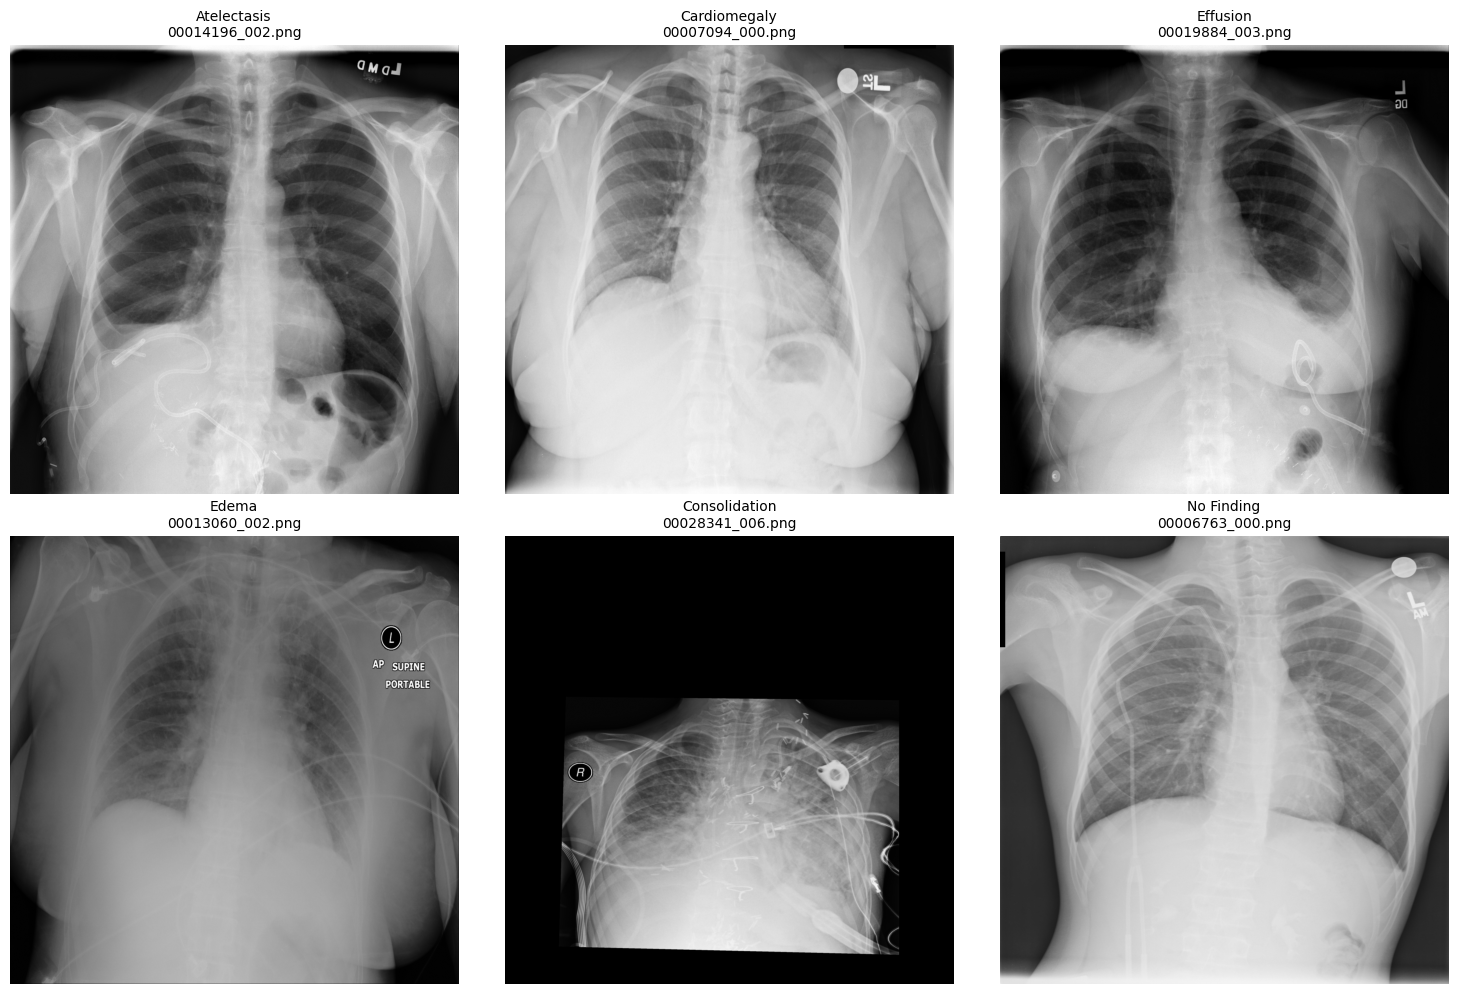

In [17]:

from PIL import Image

sample_labels = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Edema",
    "Consolidation",
    "No Finding"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, label in zip(axes.flatten(), sample_labels):

    sample = df[
        df["Finding Labels"].apply(
            lambda x: label in x.split("|")
        )
    ].sample(1, random_state=42).iloc[0]

    img = Image.open(sample["Image Path"])

    ax.imshow(img, cmap="gray")
    ax.set_title(
        f"{label}\n{sample['Image Index']}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


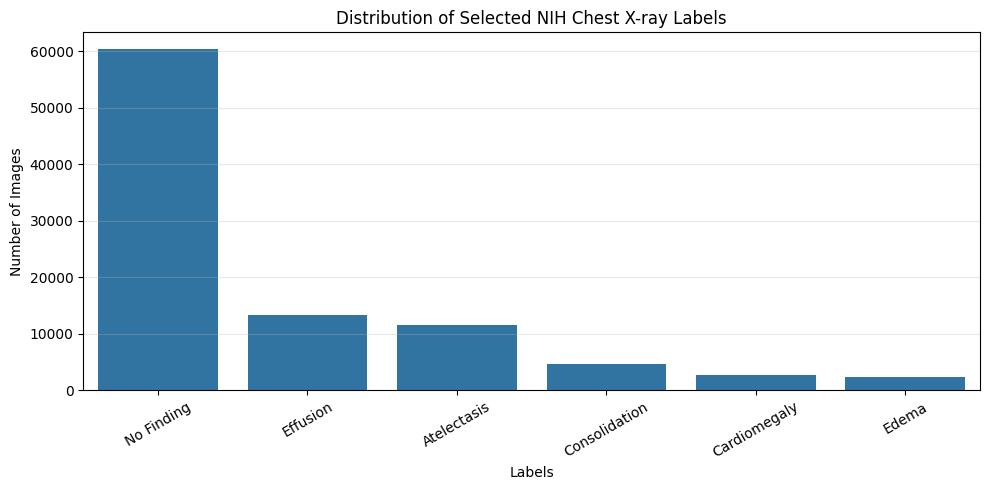


Selected Label Counts:


,Image Count
No Finding,60361
Effusion,13317
Atelectasis,11559
Consolidation,4667
Cardiomegaly,2776
Edema,2303


In [18]:

label_counts = label_matrix[selected_labels].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=label_counts.index,
    y=label_counts.values
)

plt.title("Distribution of Selected NIH Chest X-ray Labels")
plt.xlabel("Labels")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSelected Label Counts:")
display(label_counts.to_frame("Image Count"))


In [19]:

train_mask = df["Image Index"].isin(official_train)
test_mask = df["Image Index"].isin(official_test)

train_label_counts = label_matrix.loc[train_mask, selected_labels].sum()
test_label_counts = label_matrix.loc[test_mask, selected_labels].sum()

split_counts = pd.DataFrame({
    "Training + Validation": train_label_counts,
    "Testing": test_label_counts
})

split_counts["Total"] = split_counts.sum(axis=1)

print("SELECTED LABEL DISTRIBUTION IN OFFICIAL SPLITS:\n")
display(split_counts)

print("\nTRAINING + VALIDATION IMAGES:", train_mask.sum())
print("TESTING IMAGES:", test_mask.sum())


SELECTED LABEL DISTRIBUTION IN OFFICIAL SPLITS:



,Training + Validation,Testing,Total
Atelectasis,8280,3279,11559
Cardiomegaly,1707,1069,2776
Effusion,8659,4658,13317
Edema,1378,925,2303
Consolidation,2852,1815,4667
No Finding,50500,9861,60361



TRAINING + VALIDATION IMAGES: 86524
TESTING IMAGES: 25596


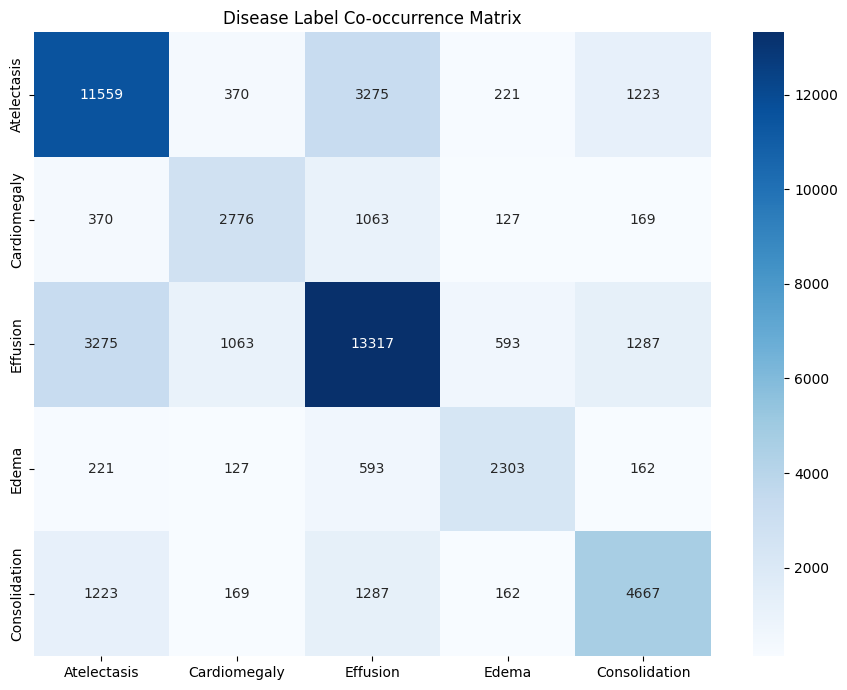

Co-occurrence matrix:


,Atelectasis,Cardiomegaly,Effusion,Edema,Consolidation
Atelectasis,11559,370,3275,221,1223
Cardiomegaly,370,2776,1063,127,169
Effusion,3275,1063,13317,593,1287
Edema,221,127,593,2303,162
Consolidation,1223,169,1287,162,4667


In [20]:

disease_labels = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Edema",
    "Consolidation"
]

co_occurrence = label_matrix[disease_labels].T.dot(
    label_matrix[disease_labels]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    co_occurrence,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Disease Label Co-occurrence Matrix")
plt.tight_layout()
plt.show()

print("Co-occurrence matrix:")
display(co_occurrence)


In [21]:

from PIL import Image

sample_paths = df["Image Path"].sample(
    n=500, random_state=42
).tolist()

image_sizes = []
image_modes = []
corrupted_images = 0

for path in sample_paths:
    try:
        with Image.open(path) as img:
            image_sizes.append(img.size)
            image_modes.append(img.mode)
    except Exception:
        corrupted_images += 1

size_counts = Counter(image_sizes)

print("Images inspected:", len(sample_paths))
print("Corrupted images:", corrupted_images)

print("\nMost common original dimensions:")
display(
    pd.Series(size_counts)
    .sort_values(ascending=False)
    .head(10)
    .to_frame("Image Count")
)

print("\nImage modes:")
print(Counter(image_modes))

print("\nView Position distribution:")
display(df["View Position"].value_counts().to_frame("Image Count"))


Images inspected: 500
Corrupted images: 0

Most common original dimensions:


,,Image Count
1024,1024,500



Image modes:
Counter({'L': 498, 'RGBA': 2})

View Position distribution:


,Image Count
View Position,
PA,67310
AP,44810


In [24]:

# Reset index to align both dataframes
train_val_df = df.loc[train_mask].copy()

train_val_labels = label_matrix.loc[train_mask, selected_labels].copy()

# Combine patient IDs with binary labels
patient_label_data = pd.concat(
    [
        train_val_df[["Patient ID"]].reset_index(drop=True),
        train_val_labels.reset_index(drop=True)
    ],
    axis=1
)

# Patient-level label presence
patient_label_data = (
    patient_label_data.groupby("Patient ID")[selected_labels]
    .max()
)

print("TRAIN + VALIDATION PATIENTS:",
      patient_label_data.shape[0])

print("\nPATIENTS HAVING EACH SELECTED LABEL:")
display(
    patient_label_data.sum()
    .sort_values(ascending=False)
    .to_frame("Unique Patients")
)

print("\nTRAIN + VALIDATION IMAGE COUNTS:")
print("Total images:", len(train_val_df))
print("Unique patients:", train_val_df["Patient ID"].nunique())


TRAIN + VALIDATION PATIENTS: 28008

PATIENTS HAVING EACH SELECTED LABEL:


,Unique Patients
No Finding,22350
Atelectasis,4182
Effusion,3502
Consolidation,1617
Cardiomegaly,1228
Edema,747



TRAIN + VALIDATION IMAGE COUNTS:
Total images: 86524
Unique patients: 28008


In [25]:
# Check patient-level label combinations

patient_label_data["Label Combination"] = (
    patient_label_data[selected_labels]
    .apply(
        lambda row: "|".join(
            label for label in selected_labels if row[label] == 1
        ),
        axis=1
    )
)

print("MOST COMMON PATIENT LABEL COMBINATIONS:")
display(
    patient_label_data["Label Combination"]
    .value_counts()
    .head(15)
    .to_frame("Number of Patients")
)

print("\nPATIENT IMAGE COUNT DISTRIBUTION:")
patient_image_counts = (
    train_val_df.groupby("Patient ID")
    .size()
)

display(patient_image_counts.describe().to_frame("Images per Patient"))

MOST COMMON PATIENT LABEL COMBINATIONS:


,Number of Patients
Label Combination,
No Finding,17785
,3293
Atelectasis|No Finding,1138
Atelectasis,807
Atelectasis|Effusion|No Finding,707
Effusion|No Finding,593
Effusion,469
Atelectasis|Effusion|Consolidation|No Finding,390
Cardiomegaly,323



PATIENT IMAGE COUNT DISTRIBUTION:


,Images per Patient
count,28008.000000
mean,3.089260
std,5.003619
min,1.000000
25%,1.000000
50%,1.000000
75%,3.000000
max,109.000000


In [26]:
# Check image counts for patients having each selected label

patient_image_counts = train_val_df.groupby("Patient ID").size()

label_patient_stats = []

for label in selected_labels:
    patients_with_label = patient_label_data[
        patient_label_data[label] == 1
    ].index

    images_for_label_patients = patient_image_counts.loc[
        patient_image_counts.index.isin(patients_with_label)
    ]

    label_patient_stats.append({
        "Label": label,
        "Patients": len(patients_with_label),
        "Total Images": images_for_label_patients.sum(),
        "Average Images per Patient": round(
            images_for_label_patients.mean(), 2
        )
    })

label_patient_stats_df = pd.DataFrame(label_patient_stats)

display(label_patient_stats_df)

,Label,Patients,Total Images,Average Images per Patient
0,Atelectasis,4182,34069,8.15
1,Cardiomegaly,1228,9008,7.34
2,Effusion,3502,31815,9.08
3,Edema,747,11692,15.65
4,Consolidation,1617,19551,12.09
5,No Finding,22350,78569,3.52


In [27]:
try:
    from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
    print("Iterative stratification is available!")
except ImportError:
    print("Iterative stratification is not installed.")

Iterative stratification is not installed.


In [28]:
!pip install iterative-stratification

In [29]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

# Patient-level multi-label data
X = np.zeros((len(patient_label_data), 1))
y = patient_label_data[selected_labels].values

# Select approximately 35% patients
msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.65,
    random_state=42
)

subset_indices, _ = next(msss.split(X, y))

selected_patient_ids = patient_label_data.index[subset_indices]

# Include all images belonging to selected patients
trial_subset_df = train_val_df[
    train_val_df["Patient ID"].isin(selected_patient_ids)
].copy()

# Check subset size
print("SELECTED PATIENTS:", len(selected_patient_ids))
print("SELECTED IMAGES:", len(trial_subset_df))

print("\nIMAGE LABEL DISTRIBUTION:")
display(
    label_matrix.loc[
        trial_subset_df.index, selected_labels
    ].sum().sort_values(ascending=False).to_frame("Images")
)

print("\nPATIENT LABEL DISTRIBUTION:")
display(
    patient_label_data.loc[
        selected_patient_ids, selected_labels
    ].sum().to_frame("Patients")
)

SELECTED PATIENTS: 9802
SELECTED IMAGES: 29973

IMAGE LABEL DISTRIBUTION:


,Images
No Finding,17496
Effusion,3041
Atelectasis,2834
Consolidation,1003
Cardiomegaly,600
Edema,501



PATIENT LABEL DISTRIBUTION:


,Patients
Atelectasis,1464
Cardiomegaly,430
Effusion,1226
Edema,261
Consolidation,566
No Finding,7822


In [30]:
# Prepare selected patient-level labels
selected_patient_labels = patient_label_data.loc[
    selected_patient_ids, selected_labels
]

X = np.zeros((len(selected_patient_labels), 1))
y = selected_patient_labels.values

# Split patients into 85% train and 15% validation
msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_indices, val_indices = next(msss.split(X, y))

train_patient_ids = selected_patient_labels.index[train_indices]
val_patient_ids = selected_patient_labels.index[val_indices]

# Assign all images of each patient to one split
train_df = trial_subset_df[
    trial_subset_df["Patient ID"].isin(train_patient_ids)
].copy()

val_df = trial_subset_df[
    trial_subset_df["Patient ID"].isin(val_patient_ids)
].copy()

print("TRAINING:")
print("Patients:", len(train_patient_ids))
print("Images:", len(train_df))

print("\nVALIDATION:")
print("Patients:", len(val_patient_ids))
print("Images:", len(val_df))

print("\nPATIENT OVERLAP:",
      len(set(train_patient_ids) & set(val_patient_ids)))

print("\nTOTAL IMAGES:",
      len(train_df) + len(val_df))

TRAINING:
Patients: 8331
Images: 25679

VALIDATION:
Patients: 1471
Images: 4294

PATIENT OVERLAP: 0

TOTAL IMAGES: 29973


In [31]:
# Prepare official test dataframe
test_df = df[df["Image Index"].isin(official_test)].copy()

# Compare label distribution across all splits
split_data = {
    "Training": train_df,
    "Validation": val_df,
    "Official Test": test_df
}

for split_name, split_df in split_data.items():
    print(f"\n{split_name.upper()}")
    print("Total images:", len(split_df))

    split_labels = label_matrix.loc[
        split_df.index, selected_labels
    ]

    display(
        split_labels.sum()
        .to_frame("Positive Images")
    )


TRAINING
Total images: 25679


,Positive Images
Atelectasis,2412
Cardiomegaly,510
Effusion,2594
Edema,443
Consolidation,861
No Finding,14961



VALIDATION
Total images: 4294


,Positive Images
Atelectasis,422
Cardiomegaly,90
Effusion,447
Edema,58
Consolidation,142
No Finding,2535



OFFICIAL TEST
Total images: 25596


,Positive Images
Atelectasis,3279
Cardiomegaly,1069
Effusion,4658
Edema,925
Consolidation,1815
No Finding,9861


In [32]:
# Create final metadata for each split

def prepare_split(split_df):
    split_labels = label_matrix.loc[
        split_df.index, selected_labels
    ]

    final_df = pd.concat(
        [
            split_df[
                ["Image Index", "Image Path", "Patient ID",
                 "View Position"]
            ].reset_index(drop=True),
            split_labels.reset_index(drop=True)
        ],
        axis=1
    )

    return final_df


train_final = prepare_split(train_df)
val_final = prepare_split(val_df)
test_final = prepare_split(test_df)

# Save CSV files
train_final.to_csv(
    "/kaggle/working/train_metadata.csv", index=False
)

val_final.to_csv(
    "/kaggle/working/validation_metadata.csv", index=False
)

test_final.to_csv(
    "/kaggle/working/test_metadata.csv", index=False
)

print("Metadata files saved successfully!")

print("\nTrain:", train_final.shape)
print("Validation:", val_final.shape)
print("Test:", test_final.shape)

print("\nSaved files:")
print("train_metadata.csv")
print("validation_metadata.csv")
print("test_metadata.csv")

Metadata files saved successfully!

Train: (25679, 10)
Validation: (4294, 10)
Test: (25596, 10)

Saved files:
train_metadata.csv
validation_metadata.csv
test_metadata.csv


# 02. Image Preprocessing

In this section, we will prepare the chest X-ray images
for training the DenseNet121 deep learning model.
 
- Load image metadata
- Read and convert images to RGB
- Resize images to 224 × 224
- Apply ImageNet normalization
- Prepare data augmentation

In [33]:
# Load final dataset metadata

train_final = pd.read_csv("/kaggle/working/train_metadata.csv")
val_final = pd.read_csv("/kaggle/working/validation_metadata.csv")
test_final = pd.read_csv("/kaggle/working/test_metadata.csv")

print("Metadata loaded successfully!")

print("\nTraining shape:", train_final.shape)
print("Validation shape:", val_final.shape)
print("Testing shape:", test_final.shape)

print("\nTraining data sample:")
display(train_final.head())

Metadata loaded successfully!

Training shape: (25679, 10)
Validation shape: (4294, 10)
Testing shape: (25596, 10)

Training data sample:


,Image Index,Image Path,Patient ID,View Position,Atelectasis,Cardiomegaly,Effusion,Edema,Consolidation,No Finding
0,00000001_000.png,/kaggle/input/datasets/nih-chest-xrays/data/im...,1,PA,0,1,0,0,0,0
1,00000001_001.png,/kaggle/input/datasets/nih-chest-xrays/data/im...,1,PA,0,1,0,0,0,0
2,00000001_002.png,/kaggle/input/datasets/nih-chest-xrays/data/im...,1,PA,0,1,1,0,0,0
3,00000004_000.png,/kaggle/input/datasets/nih-chest-xrays/data/im...,4,AP,0,0,0,0,0,0
4,00000006_000.png,/kaggle/input/datasets/nih-chest-xrays/data/im...,6,PA,0,0,0,0,0,1


In [34]:
# Check missing values
print("MISSING VALUES:")
display(
    train_final.isnull().sum().to_frame("Missing Values")
)

# Check image path availability
print("\nIMAGE PATH VERIFICATION:")

train_paths_exist = train_final["Image Path"].apply(
    lambda path: os.path.isfile(path)
)

print("Total images:", len(train_final))
print("Existing image files:", train_paths_exist.sum())
print("Missing image files:", (~train_paths_exist).sum())

# Check label values
print("\nUNIQUE LABEL VALUES:")

display(
    train_final[selected_labels].nunique().to_frame(
        "Unique Values"
    )
)

MISSING VALUES:


,Missing Values
Image Index,0
Image Path,0
Patient ID,0
View Position,0
Atelectasis,0
Cardiomegaly,0
Effusion,0
Edema,0
Consolidation,0
No Finding,0



IMAGE PATH VERIFICATION:
Total images: 25679
Existing image files: 25679
Missing image files: 0

UNIQUE LABEL VALUES:


,Unique Values
Atelectasis,2
Cardiomegaly,2
Effusion,2
Edema,2
Consolidation,2
No Finding,2


In [35]:
from torchvision import transforms

IMG_SIZE = 224

# Training transformations
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation and testing transformations
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Image transformations defined successfully!")
print("Image size:", IMG_SIZE, "x", IMG_SIZE)

Image transformations defined successfully!
Image size: 224 x 224


In [36]:
from torch.utils.data import Dataset

class ChestXrayDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.label_columns = selected_labels

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        # Load image
        image = Image.open(row["Image Path"]).convert("RGB")

        # Apply transformations
        if self.transform:
            image = self.transform(image)

        # Get multi-label targets
        labels = row[self.label_columns].values.astype("float32")
        labels = torch.tensor(labels, dtype=torch.float32)

        return image, labels


print("Custom Chest X-ray Dataset class created successfully!")

Custom Chest X-ray Dataset class created successfully!


In [38]:
# Create PyTorch datasets
import torch

print("PyTorch imported successfully!")
train_dataset = ChestXrayDataset(
    dataframe=train_final,
    transform=train_transform
)

val_dataset = ChestXrayDataset(
    dataframe=val_final,
    transform=eval_transform
)

test_dataset = ChestXrayDataset(
    dataframe=test_final,
    transform=eval_transform
)

print("Datasets created successfully!")

print("\nTraining samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

# Inspect one training sample
sample_image, sample_labels = train_dataset[0]

print("\nSample image shape:", sample_image.shape)
print("Sample labels:", sample_labels)
print("Image data type:", sample_image.dtype)
print("Label data type:", sample_labels.dtype)

PyTorch imported successfully!
Datasets created successfully!

Training samples: 25679
Validation samples: 4294
Testing samples: 25596

Sample image shape: torch.Size([3, 224, 224])
Sample labels: tensor([0., 1., 0., 0., 0., 0.])
Image data type: torch.float32
Label data type: torch.float32


In [39]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32
NUM_WORKERS = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available()
)

print("DataLoaders created successfully!")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 803
Validation batches: 135
Testing batches: 800


In [40]:
# Get one batch from training DataLoader

images, labels = next(iter(train_loader))

print("IMAGE BATCH SHAPE:", images.shape)
print("LABEL BATCH SHAPE:", labels.shape)

print("\nIMAGE DATA TYPE:", images.dtype)
print("LABEL DATA TYPE:", labels.dtype)

print("\nMINIMUM IMAGE VALUE:", images.min().item())
print("MAXIMUM IMAGE VALUE:", images.max().item())

print("\nFIRST IMAGE LABELS:", labels[0])

IMAGE BATCH SHAPE: torch.Size([32, 3, 224, 224])
LABEL BATCH SHAPE: torch.Size([32, 6])

IMAGE DATA TYPE: torch.float32
LABEL DATA TYPE: torch.float32

MINIMUM IMAGE VALUE: -2.1179039478302
MAXIMUM IMAGE VALUE: 2.640000104904175

FIRST IMAGE LABELS: tensor([0., 0., 0., 0., 0., 1.])


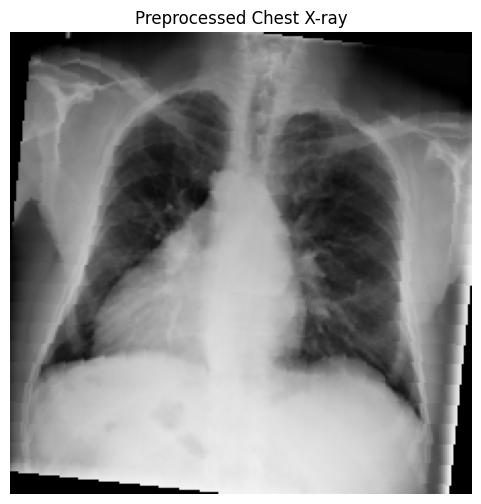

Labels:
- Cardiomegaly


In [41]:
# Visualize one preprocessed training image

import matplotlib.pyplot as plt

image, label = train_dataset[0]

# Reverse ImageNet normalization
mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_image = image * std + mean
display_image = display_image.permute(1, 2, 0).numpy()
display_image = display_image.clip(0, 1)

plt.figure(figsize=(6, 6))
plt.imshow(display_image)
plt.title("Preprocessed Chest X-ray")
plt.axis("off")
plt.show()

print("Labels:")
for name, value in zip(selected_labels, label.tolist()):
    if value == 1:
        print("-", name)

# 03. DenseNet121 Model Architecture

In [42]:
import torch.nn as nn
from torchvision import models
from torchvision.models import DenseNet121_Weights

# Select device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained DenseNet121
weights = DenseNet121_Weights.DEFAULT
model = models.densenet121(weights=weights)

# Freeze pretrained feature extraction layers initially
for param in model.features.parameters():
    param.requires_grad = False

# Replace final classification layer
in_features = model.classifier.in_features

model.classifier = nn.Linear(
    in_features,
    len(selected_labels)
)

# Move model to GPU or CPU
model = model.to(device)

print("DenseNet121 loaded successfully!")
print("Device:", device)
print("Input features:", in_features)
print("Output classes:", len(selected_labels))
print("Output labels:", selected_labels)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 229MB/s]


DenseNet121 loaded successfully!
Device: cuda
Input features: 1024
Output classes: 6
Output labels: ['Atelectasis', 'Cardiomegaly', 'Effusion', 'Edema', 'Consolidation', 'No Finding']


In [43]:
# Count total and trainable parameters

total_params = sum(
    param.numel() for param in model.parameters()
)

trainable_params = sum(
    param.numel()
    for param in model.parameters()
    if param.requires_grad
)

frozen_params = total_params - trainable_params

print("MODEL PARAMETER SUMMARY")
print("-----------------------")
print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")
print("Frozen parameters:", f"{frozen_params:,}")

print("\nCLASSIFIER LAYER:")
print(model.classifier)

MODEL PARAMETER SUMMARY
-----------------------
Total parameters: 6,960,006
Trainable parameters: 6,150
Frozen parameters: 6,953,856

CLASSIFIER LAYER:
Linear(in_features=1024, out_features=6, bias=True)


## Configure Loss Function and Optimizer

### used BCEWithLogitsLoss ,instead of Softmax or CrossEntropyLoss .

In [44]:
# Define loss function
criterion = nn.BCEWithLogitsLoss()

# Define optimizer
optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Learning rate:", 0.001)

Loss function: BCEWithLogitsLoss()
Optimizer: Adam
Learning rate: 0.001


## class weights

In [45]:
# Calculate positive and negative samples per class

positive_counts = train_final[selected_labels].sum()
negative_counts = len(train_final) - positive_counts

# Calculate positive weights
pos_weights = negative_counts / positive_counts

class_balance_df = pd.DataFrame({
    "Positive Samples": positive_counts,
    "Negative Samples": negative_counts,
    "Positive Weight": pos_weights.round(2)
})

display(class_balance_df)

,Positive Samples,Negative Samples,Positive Weight
Atelectasis,2412,23267,9.65
Cardiomegaly,510,25169,49.35
Effusion,2594,23085,8.90
Edema,443,25236,56.97
Consolidation,861,24818,28.82
No Finding,14961,10718,0.72


In [46]:
# Limit extreme positive weights
pos_weights_clipped = pos_weights.clip(upper=10)

# Convert weights into PyTorch tensor
pos_weight_tensor = torch.tensor(
    pos_weights_clipped.values,
    dtype=torch.float32
).to(device)

# Update weighted loss function
criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)

print("Weighted loss function configured!")
print("\nClass weights:")

for label, weight in zip(selected_labels, pos_weight_tensor):
    print(f"{label}: {weight.item():.2f}")

Weighted loss function configured!

Class weights:
Atelectasis: 9.65
Cardiomegaly: 10.00
Effusion: 8.90
Edema: 10.00
Consolidation: 10.00
No Finding: 0.72


## Model training

In [47]:
# Training configuration
NUM_EPOCHS = 10
LEARNING_RATE = 0.001

# Track best validation loss
best_val_loss = float("inf")

# Store training history
history = {
    "train_loss": [],
    "val_loss": []
}

print("Training configuration ready!")
print("Epochs:", NUM_EPOCHS)
print("Learning Rate:", LEARNING_RATE)
print("Device:", device)

Training configuration ready!
Epochs: 10
Learning Rate: 0.001
Device: cuda


In [48]:
import copy

for epoch in range(NUM_EPOCHS):

    # Training phase
    model.train()
    running_train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)

    # Validation phase
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)

    # Save losses
    history["train_loss"].append(epoch_train_loss)
    history["val_loss"].append(epoch_val_loss)

    # Save best model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_weights = copy.deepcopy(model.state_dict())

        torch.save(
            best_model_weights,
            "/kaggle/working/best_densenet121.pth"
        )

    print(
        f"Epoch [{epoch+1}/{NUM_EPOCHS}] "
        f"| Train Loss: {epoch_train_loss:.4f} "
        f"| Val Loss: {epoch_val_loss:.4f}"
    )

print("\nTraining completed!")
print(f"Best Validation Loss: {best_val_loss:.4f}")

Epoch [1/10] | Train Loss: 0.7427 | Val Loss: 0.7152
Epoch [2/10] | Train Loss: 0.7056 | Val Loss: 0.7325
Epoch [3/10] | Train Loss: 0.6936 | Val Loss: 0.7220
Epoch [4/10] | Train Loss: 0.6920 | Val Loss: 0.6991
Epoch [5/10] | Train Loss: 0.6872 | Val Loss: 0.7430
Epoch [6/10] | Train Loss: 0.6880 | Val Loss: 0.7026
Epoch [7/10] | Train Loss: 0.6845 | Val Loss: 0.7178
Epoch [8/10] | Train Loss: 0.6827 | Val Loss: 0.7053
Epoch [9/10] | Train Loss: 0.6833 | Val Loss: 0.7491
Epoch [10/10] | Train Loss: 0.6804 | Val Loss: 0.6946

Training completed!
Best Validation Loss: 0.6946


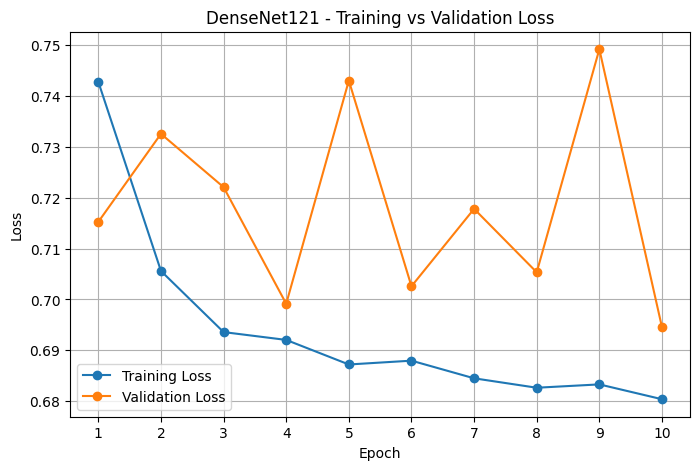

In [49]:
plt.figure(figsize=(8, 5))

plt.plot(history["train_loss"], marker="o", label="Training Loss")
plt.plot(history["val_loss"], marker="o", label="Validation Loss")

plt.title("DenseNet121 - Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(10), range(1, 11))
plt.legend()
plt.grid(True)
plt.show()

In [50]:
# Load the best saved model weights
best_weights = torch.load(
    "/kaggle/working/best_densenet121.pth",
    map_location=device
)

model.load_state_dict(best_weights)
model = model.to(device)
model.eval()

print("Best model weights restored successfully!")
print("Model is ready for evaluation.")
print("Best Validation Loss:", round(best_val_loss, 4))

Best model weights restored successfully!
Model is ready for evaluation.
Best Validation Loss: 0.6946


# Model Evaluation

In [51]:
# Generate predictions on test dataset
model.eval()

all_labels = []
all_probabilities = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        probabilities = torch.sigmoid(outputs)

        all_labels.append(labels.numpy())
        all_probabilities.append(probabilities.cpu().numpy())

# Combine all batches
y_true = np.concatenate(all_labels, axis=0)
y_probs = np.concatenate(all_probabilities, axis=0)

print("Test predictions generated successfully!")
print("Actual labels shape:", y_true.shape)
print("Predicted probabilities shape:", y_probs.shape)
print("\nSample probabilities:")
print(y_probs[:3])

Test predictions generated successfully!
Actual labels shape: (25596, 6)
Predicted probabilities shape: (25596, 6)

Sample probabilities:
[[0.58530015 0.18177837 0.55875075 0.03327041 0.2767467  0.36401647]
 [0.35935682 0.10981585 0.26480153 0.06691647 0.10848521 0.58452564]
 [0.7610254  0.07820009 0.5606387  0.05631293 0.31306794 0.38548833]]


In [52]:
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd

results = []

for i, label in enumerate(selected_labels):

    roc_auc = roc_auc_score(y_true[:, i], y_probs[:, i])

    pr_auc = average_precision_score(y_true[:, i], y_probs[:, i])

    results.append({
        "Label": label,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })

auc_results = pd.DataFrame(results)

print("Per-Label Evaluation Results:")
display(auc_results.round(4))

Per-Label Evaluation Results:


,Label,ROC-AUC,PR-AUC
0,Atelectasis,0.6354,0.1995
1,Cardiomegaly,0.6860,0.1072
2,Effusion,0.7023,0.3104
3,Edema,0.7630,0.0909
4,Consolidation,0.6737,0.1158
5,No Finding,0.6687,0.5717


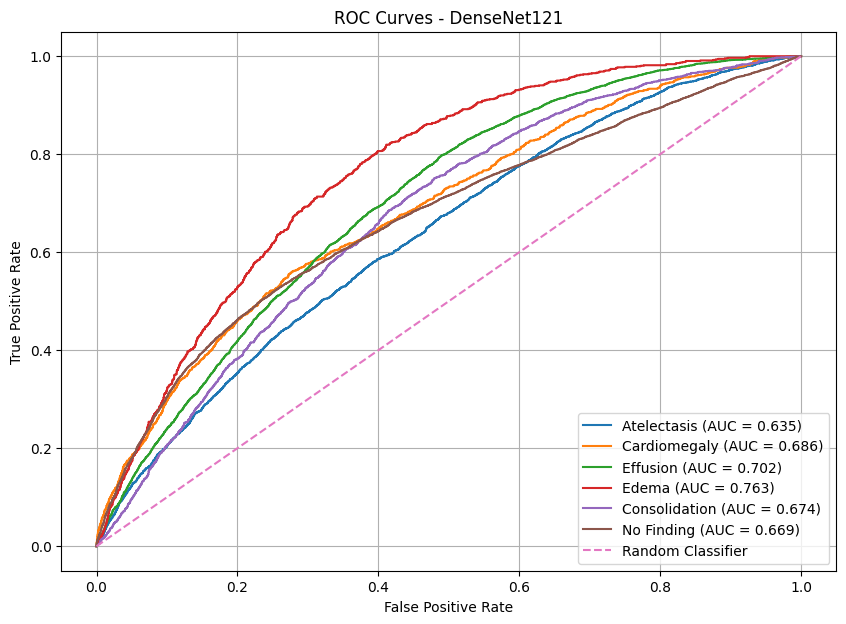

In [53]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for i, label in enumerate(selected_labels):

    fpr, tpr, thresholds = roc_curve(
        y_true[:, i],
        y_probs[:, i]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{label} (AUC = {auc_results.loc[i, 'ROC-AUC']:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.title("ROC Curves - DenseNet121")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

In [54]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

# Convert probabilities into binary predictions
y_pred = (y_probs >= 0.5).astype(int)

# Calculate per-label metrics
precision = precision_score(y_true, y_pred, average=None, zero_division=0)
recall = recall_score(y_true, y_pred, average=None, zero_division=0)
f1 = f1_score(y_true, y_pred, average=None, zero_division=0)

# Create results table
metrics_results = pd.DataFrame({
    "Label": selected_labels,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
})

print("Per-Label Classification Metrics:")
display(metrics_results.round(4))

print("\nOverall Macro F1-Score:",
      round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4))

print("Overall Micro F1-Score:",
      round(f1_score(y_true, y_pred, average="micro", zero_division=0), 4))

Per-Label Classification Metrics:


,Label,Precision,Recall,F1-Score
0,Atelectasis,0.1616,0.7511,0.2659
1,Cardiomegaly,0.1554,0.1441,0.1495
2,Effusion,0.2618,0.8139,0.3962
3,Edema,0.0971,0.4486,0.1596
4,Consolidation,0.1098,0.7052,0.1900
5,No Finding,0.6155,0.4117,0.4934



Overall Macro F1-Score: 0.2758
Overall Micro F1-Score: 0.325


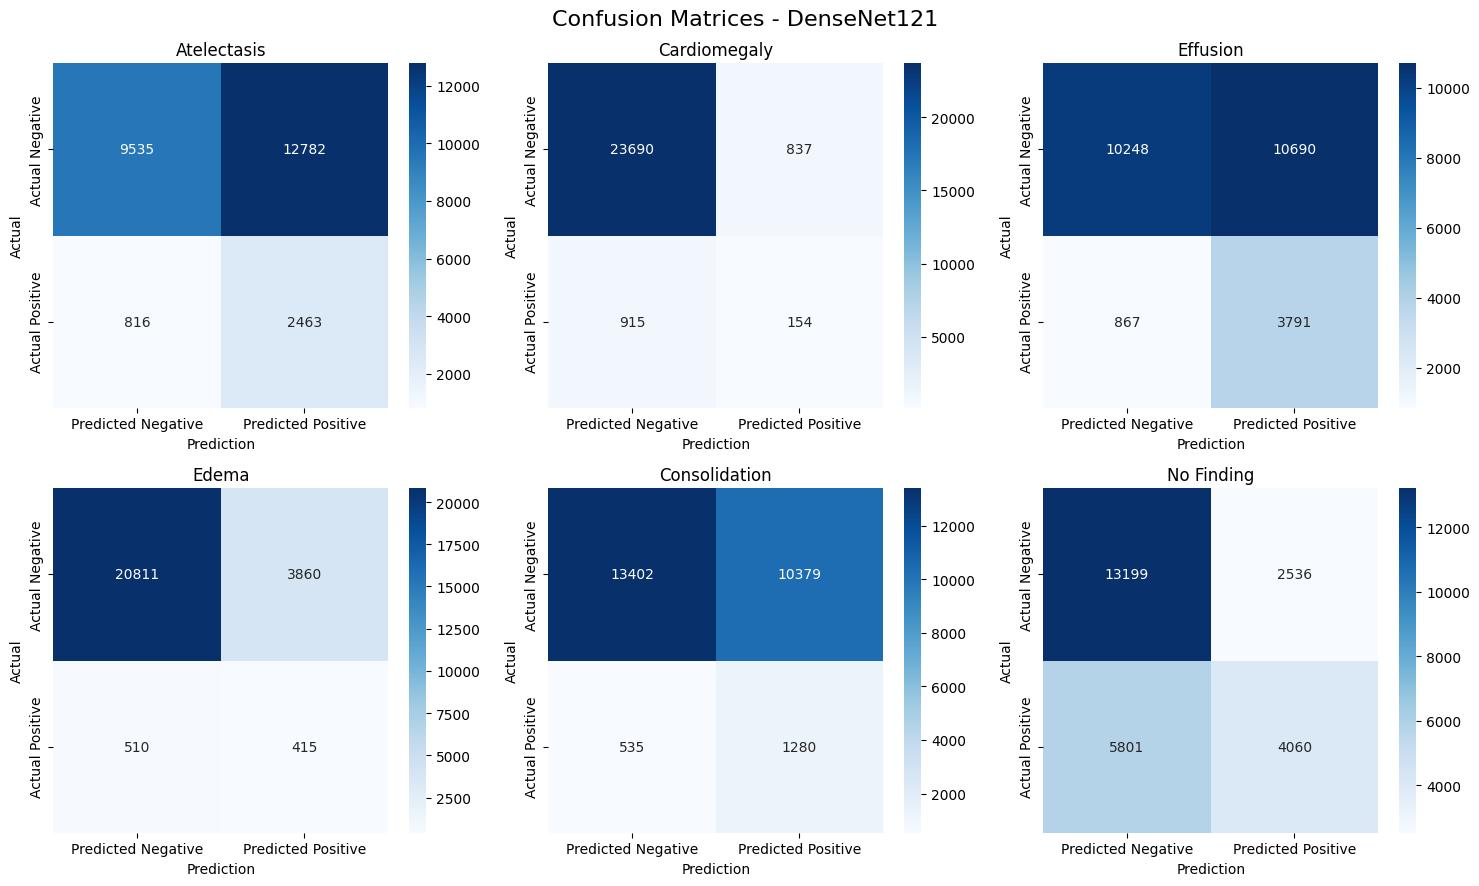

In [55]:
from sklearn.metrics import multilabel_confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = multilabel_confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, label in enumerate(selected_labels):

    sns.heatmap(
        cm[i],
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Predicted Negative", "Predicted Positive"],
        yticklabels=["Actual Negative", "Actual Positive"],
        ax=axes[i]
    )

    axes[i].set_title(label)
    axes[i].set_xlabel("Prediction")
    axes[i].set_ylabel("Actual")

plt.suptitle("Confusion Matrices - DenseNet121", fontsize=16)
plt.tight_layout()
plt.show()

In [56]:
from sklearn.metrics import accuracy_score

# Exact match accuracy
exact_accuracy = accuracy_score(y_true, y_pred)

# Hamming accuracy: percentage of correctly predicted labels
hamming_accuracy = 1 - np.mean(y_true != y_pred)

print(f"Exact Match Accuracy: {exact_accuracy * 100:.2f}%")
print(f"Hamming Accuracy: {hamming_accuracy * 100:.2f}%")

Exact Match Accuracy: 18.14%
Hamming Accuracy: 67.10%


In [57]:
model.eval()

val_labels = []
val_probabilities = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        probabilities = torch.sigmoid(outputs)

        val_labels.append(labels.numpy())
        val_probabilities.append(probabilities.cpu().numpy())

y_val_true = np.concatenate(val_labels, axis=0)
y_val_probs = np.concatenate(val_probabilities, axis=0)

print("Validation predictions generated!")
print("Actual labels shape:", y_val_true.shape)
print("Predicted probabilities shape:", y_val_probs.shape)

Validation predictions generated!
Actual labels shape: (4294, 6)
Predicted probabilities shape: (4294, 6)


## Threshold Optimization

In [58]:
from sklearn.metrics import f1_score

threshold_results = []

for i, label in enumerate(selected_labels):

    best_threshold = 0.5
    best_f1 = 0

    for threshold in np.arange(0.1, 0.91, 0.01):

        predictions = (y_val_probs[:, i] >= threshold).astype(int)

        score = f1_score(
            y_val_true[:, i],
            predictions,
            zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_threshold = threshold

    threshold_results.append({
        "Label": label,
        "Best Threshold": best_threshold,
        "Validation F1": best_f1
    })

threshold_df = pd.DataFrame(threshold_results)

print("Optimized Thresholds:")
display(threshold_df.round(4))

Optimized Thresholds:


,Label,Best Threshold,Validation F1
0,Atelectasis,0.51,0.2889
1,Cardiomegaly,0.70,0.1296
2,Effusion,0.67,0.3993
3,Edema,0.71,0.1224
4,Consolidation,0.71,0.1609
5,No Finding,0.33,0.7584


In [59]:
# Extract optimized thresholds
best_thresholds = threshold_df["Best Threshold"].values

# Generate optimized test predictions
y_pred_tuned = np.zeros_like(y_probs)

for i, threshold in enumerate(best_thresholds):
    y_pred_tuned[:, i] = (
        y_probs[:, i] >= threshold
    ).astype(int)

# Calculate metrics
tuned_precision = precision_score(
    y_true, y_pred_tuned, average=None, zero_division=0
)

tuned_recall = recall_score(
    y_true, y_pred_tuned, average=None, zero_division=0
)

tuned_f1 = f1_score(
    y_true, y_pred_tuned, average=None, zero_division=0
)

# Results table
tuned_results = pd.DataFrame({
    "Label": selected_labels,
    "Threshold": best_thresholds,
    "Precision": tuned_precision,
    "Recall": tuned_recall,
    "F1-Score": tuned_f1
})

display(tuned_results.round(4))

# Overall metrics
print("Optimized Macro F1:",
      round(f1_score(y_true, y_pred_tuned, average="macro", zero_division=0), 4))

print("Optimized Micro F1:",
      round(f1_score(y_true, y_pred_tuned, average="micro", zero_division=0), 4))

print("Exact Match Accuracy:",
      round(accuracy_score(y_true, y_pred_tuned) * 100, 2), "%")

print("Hamming Accuracy:",
      round((1 - np.mean(y_true != y_pred_tuned)) * 100, 2), "%")

,Label,Threshold,Precision,Recall,F1-Score
0,Atelectasis,0.51,0.1623,0.7365,0.2660
1,Cardiomegaly,0.70,0.2781,0.0440,0.0759
2,Effusion,0.67,0.2965,0.5683,0.3897
3,Edema,0.71,0.1173,0.1481,0.1309
4,Consolidation,0.71,0.1306,0.3515,0.1904
5,No Finding,0.33,0.4973,0.6592,0.5669


Optimized Macro F1: 0.27
Optimized Micro F1: 0.3828
Exact Match Accuracy: 22.12 %
Hamming Accuracy: 73.99 %


In [60]:
# Save baseline and threshold-tuned evaluation results

baseline_results = metrics_results.copy()
baseline_results.to_csv(
    "/kaggle/working/baseline_results.csv",
    index=False
)

tuned_results.to_csv(
    "/kaggle/working/tuned_results.csv",
    index=False
)

threshold_df.to_csv(
    "/kaggle/working/optimized_thresholds.csv",
    index=False
)

print("Baseline results saved!")
print("Tuned results saved!")
print("Optimized thresholds saved!")

Baseline results saved!
Tuned results saved!
Optimized thresholds saved!


# Fine-tuning

In [61]:
# Unfreeze the last DenseNet block
for name, param in model.features.named_parameters():
    if name.startswith("denseblock4") or name.startswith("norm5"):
        param.requires_grad = True

# Count trainable and frozen parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)
frozen_params = total_params - trainable_params

print("Fine-tuning layers configured!")
print("Trainable parameters:", f"{trainable_params:,}")
print("Frozen parameters:", f"{frozen_params:,}")

Fine-tuning layers configured!
Trainable parameters: 2,166,278
Frozen parameters: 4,793,728


In [62]:
# Fine-tuning configuration
FINE_TUNE_EPOCHS = 10
FINE_TUNE_LR = 0.0001

# Optimize only trainable parameters
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=FINE_TUNE_LR
)

# Reset best validation loss for fine-tuning
best_finetune_val_loss = float("inf")

# Separate history
finetune_history = {
    "train_loss": [],
    "val_loss": []
}

print("Fine-tuning optimizer configured!")
print("Epochs:", FINE_TUNE_EPOCHS)
print("Learning Rate:", FINE_TUNE_LR)

Fine-tuning optimizer configured!
Epochs: 10
Learning Rate: 0.0001


In [63]:
import copy

for epoch in range(FINE_TUNE_EPOCHS):

    # Training phase
    model.train()
    running_train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)

    # Validation phase
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)

    finetune_history["train_loss"].append(epoch_train_loss)
    finetune_history["val_loss"].append(epoch_val_loss)

    # Save best fine-tuned model
    if epoch_val_loss < best_finetune_val_loss:
        best_finetune_val_loss = epoch_val_loss
        best_finetune_weights = copy.deepcopy(model.state_dict())

        torch.save(
            best_finetune_weights,
            "/kaggle/working/best_finetuned_densenet121.pth"
        )

    print(
        f"Epoch [{epoch+1}/{FINE_TUNE_EPOCHS}] "
        f"| Train Loss: {epoch_train_loss:.4f} "
        f"| Val Loss: {epoch_val_loss:.4f}"
    )

print("\nFine-tuning completed!")
print("Best Fine-tuning Validation Loss:",
      round(best_finetune_val_loss, 4))

Epoch [1/10] | Train Loss: 0.6564 | Val Loss: 0.6833
Epoch [2/10] | Train Loss: 0.6149 | Val Loss: 0.6645
Epoch [3/10] | Train Loss: 0.5902 | Val Loss: 0.6625
Epoch [4/10] | Train Loss: 0.5714 | Val Loss: 0.6573
Epoch [5/10] | Train Loss: 0.5487 | Val Loss: 0.6789
Epoch [6/10] | Train Loss: 0.5338 | Val Loss: 0.6740
Epoch [7/10] | Train Loss: 0.5150 | Val Loss: 0.6818
Epoch [8/10] | Train Loss: 0.5022 | Val Loss: 0.7087
Epoch [9/10] | Train Loss: 0.4839 | Val Loss: 0.6757
Epoch [10/10] | Train Loss: 0.4706 | Val Loss: 0.6966

Fine-tuning completed!
Best Fine-tuning Validation Loss: 0.6573


In [64]:
# Load best fine-tuned weights
best_finetune_weights = torch.load(
    "/kaggle/working/best_finetuned_densenet121.pth",
    map_location=device
)

model.load_state_dict(best_finetune_weights)
model = model.to(device)
model.eval()

print("Best fine-tuned model restored successfully!")
print("Best Validation Loss:", round(best_finetune_val_loss, 4))

Best fine-tuned model restored successfully!
Best Validation Loss: 0.6573


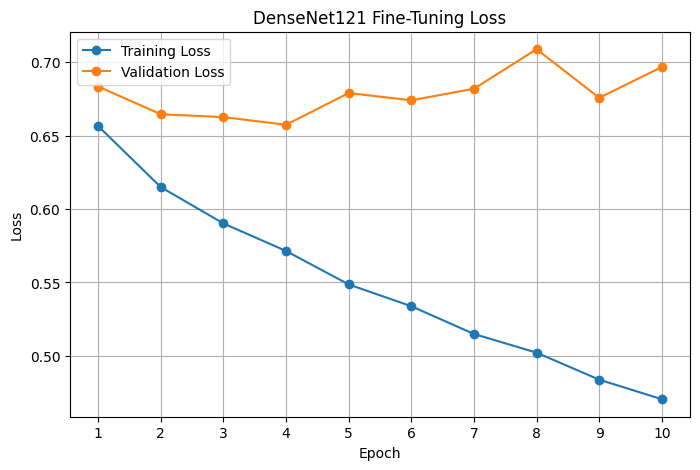

In [65]:
plt.figure(figsize=(8, 5))

plt.plot(
    finetune_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    finetune_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("DenseNet121 Fine-Tuning Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(range(10), range(1, 11))
plt.legend()
plt.grid(True)
plt.show()

# Fine-Tuning with Regularization

In [66]:
# Experiment 2: Regularized Fine-Tuning

EXPERIMENT_EPOCHS = 10
EXPERIMENT_LR = 0.00003

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=EXPERIMENT_LR,
    weight_decay=0.0001
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

best_experiment_val_loss = float("inf")

experiment_history = {
    "train_loss": [],
    "val_loss": [],
    "learning_rate": []
}

print("Experiment 2 configured!")
print("Epochs:", EXPERIMENT_EPOCHS)
print("Learning Rate:", EXPERIMENT_LR)
print("Weight Decay: 0.0001")
print("Scheduler: ReduceLROnPlateau")

Experiment 2 configured!
Epochs: 10
Learning Rate: 3e-05
Weight Decay: 0.0001
Scheduler: ReduceLROnPlateau


In [ ]:
import copy

for epoch in range(EXPERIMENT_EPOCHS):

    # Training phase
    model.train()
    running_train_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)

    # Validation phase
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)

    # Update learning rate scheduler
    scheduler.step(epoch_val_loss)

    current_lr = optimizer.param_groups[0]["lr"]

    experiment_history["train_loss"].append(epoch_train_loss)
    experiment_history["val_loss"].append(epoch_val_loss)
    experiment_history["learning_rate"].append(current_lr)

    # Save best checkpoint
    if epoch_val_loss < best_experiment_val_loss:
        best_experiment_val_loss = epoch_val_loss
        best_experiment_weights = copy.deepcopy(model.state_dict())

        torch.save(
            best_experiment_weights,
            "/kaggle/working/best_regularized_densenet121.pth"
        )

    print(
        f"Epoch [{epoch+1}/{EXPERIMENT_EPOCHS}] "
        f"| Train Loss: {epoch_train_loss:.4f} "
        f"| Val Loss: {epoch_val_loss:.4f} "
        f"| LR: {current_lr:.7f}"
    )

print("\nExperiment 2 completed!")
print("Best Validation Loss:", round(best_experiment_val_loss, 4))